In [1]:
import numpy as np
from numpy.random import default_rng
import matplotlib.pyplot as plt
from scipy.spatial import KDTree
from skimage.feature import canny
from skimage.draw import disk
from vnoise import Noise
from typing import Tuple, Set, Dict, Optional

c:\Users\gure\Documents\Projects\RealMVP\real_mvp\.venv\Lib\site-packages\vnoise\__init__.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


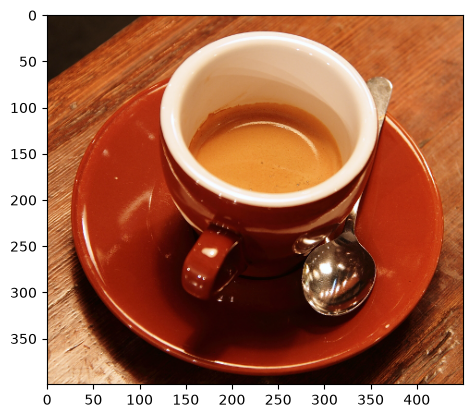

In [2]:
from skimage.data import coffee

# Just an example image
image = coffee()[:, 50:500, :]
plt.imshow(image)
plt.show()

In [3]:
# Configuration
SEED = 1337
NUM_PIECES = 10
HEIGHT, WIDTH, _ = image.shape # (400, 450, 3)
NOISE_SCALE = 40
MAX_RADIUS = 10

In [4]:
def generate_voronoi(
    num_sites: int,
    height: int, 
    width: int, 
    seed: int = None
) -> Tuple[np.ndarray, np.ndarray, Dict[int, Set[int]]]:
    """Generates a discrete Voronoi diagram on a 2D pixel grid.

    Args:
        num_sites: Number of random generating points (sites) to use.
        height: Height of the output grid in pixels.
        width: Width of the output grid in pixels.
        seed: Optional random seed for reproducible results.

    Returns:
        A tuple containing:
            - sites: Array of shape (num_sites, 2) with (x, y) coordinates of each site.
            - parts: 2D array of shape (height, width) containing the site index assigned to each pixel.
            - neighbors: Dictionary mapping each site index to a set of adjacent neighboring sites.
    """
    # Initialize random number generator and generate random site coordinates
    rng = default_rng(seed)
    xs = rng.integers(0, width, size=num_sites)
    ys = rng.integers(0, height, size=num_sites)
    sites = np.column_stack([xs, ys])

    # Build a KD-tree for fast nearest-neighbor queries
    tree = KDTree(sites)
    
    # Create a flattened coordinate grid for all pixels
    yy, xx = np.indices((height, width))
    pixel_coords = np.column_stack((xx.ravel(), yy.ravel()))
    
    # Find the closest site for every pixel and reshape back to grid dimensions
    _, closest_site_indices = tree.query(pixel_coords)
    parts = closest_site_indices.reshape(height, width)

    # Extract the adjacency graph by finding region boundaries
    neighbors = {i: set() for i in range(num_sites)}

    # Check horizontal pixel boundaries for region changes
    h_diff = parts[:, :-1] != parts[:, 1:]
    for s1, s2 in zip(parts[:, :-1][h_diff], parts[:, 1:][h_diff]):
        neighbors[s1].add(s2)
        neighbors[s2].add(s1)
        
    # Check vertical pixel boundaries for region changes
    v_diff = parts[:-1, :] != parts[1:, :]
    for s1, s2 in zip(parts[:-1, :][v_diff], parts[1:, :][v_diff]):
        neighbors[s1].add(s2)
        neighbors[s2].add(s1)
    
    return sites, parts, neighbors

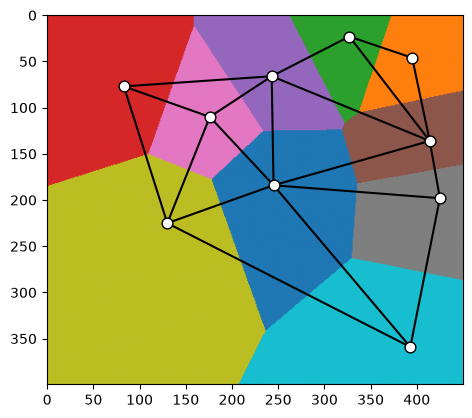

In [5]:
sites, parts, neighbor_graph = generate_voronoi(NUM_PIECES, HEIGHT, WIDTH, seed=SEED)
parts = parts.astype(np.uint8)

# Plot rasterized Voronoi cells
plt.imshow(parts, cmap='tab20', vmin=0, vmax=NUM_PIECES)

# Plot neighrbor_graph
for node, neighbors in neighbor_graph.items():
    p1 = sites[node]
    for neigh in neighbors:
        if node < neigh:
            p2 = sites[neigh]
            plt.plot([p1[0], p2[0]], [p1[1], p2[1]], color="black", linewidth=1.5, zorder=2)

plt.scatter(sites[:, 0], sites[:, 1], s=60, color='white', edgecolor='black', zorder=3)
plt.show()

In [6]:
def find_edges(
    regions: np.ndarray,
    include_boundary: bool = True
) -> np.ndarray:
    """Detects edges in a label/region matrix using the Canny edge detector.

    Args:
        regions: 2D array of region/site labels (e.g., from a Voronoi diagram).
        include_boundary: Whether to force the outer border of the image to True.

    Returns:
        A boolean 2D array of the same shape as `parts` where True indicates an edge.
    """
    # Normalize the array safely to floats for the Canny filter
    normalized_parts = regions.astype(float)
    max_val = normalized_parts.max()
    if max_val > 0:
        normalized_parts /= max_val

    edges = canny(normalized_parts)

    if include_boundary:
        edges[0, :] = True
        edges[:, 0] = True
        edges[-1, :] = True
        edges[:, -1] = True
        
    return edges

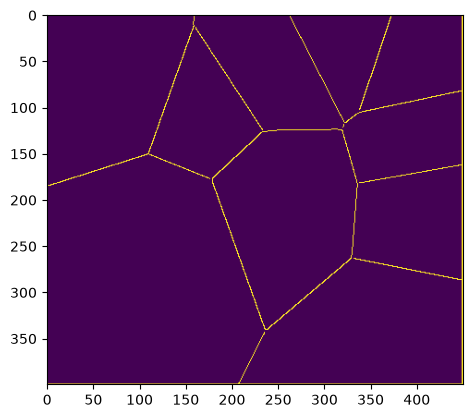

In [7]:
edges = find_edges(parts)

plt.imshow(edges)
plt.show()

In [8]:
def perlin_noise(
    height: int,
    width: int,
    scale: int,
    seed: Optional[int] = None
) -> np.ndarray:
    """Generates a 2D normalized Perlin noise grid.

    Args:
        height: Height of the output noise grid in pixels.
        width: Width of the output noise grid in pixels.
        scale: Scaling factor controlling the frequency/zoom of the noise.
        seed: Optional random seed for reproducible noise generation.

    Returns:
        A 2D float32 array of shape (height, width) with values normalized between 0 and 1.
    """
    noise_generator = Noise(seed)
    
    # Create coordinate grids scaled by the frequency factor
    x_coords = np.arange(width, dtype=np.float32) / scale
    y_coords = np.arange(height, dtype=np.float32) / scale
    
    # Generate Perlin noise in grid mode
    noise = noise_generator.noise2(y_coords, x_coords, grid_mode=True)
    
    # Normalize from [-1, 1] range to [0, 1]
    noise = (noise + 1.0) / 2.0
    
    return noise

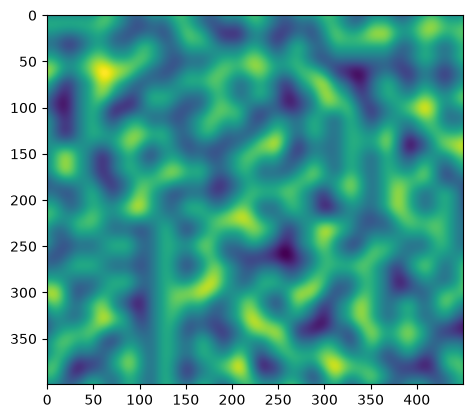

In [9]:
noise = perlin_noise(HEIGHT, WIDTH, NOISE_SCALE)
plt.imshow(noise)
plt.show()

In [10]:
def get_erosion_mask(
    edges: np.ndarray,
    noise: np.ndarray,
    max_radius: int,
) -> np.ndarray:
    """Generates a variable-width erosion mask along edges based on Perlin noise.

    Args:
        edges: Boolean 2D array indicating edge locations.
        noise: 2D array of Perlin noise values matching the grid shape.
        max_radius: Maximum radius of the erosion disk applied at edge pixels.

    Returns:
        A binary 2D array of shape (height, width) representing the erosion region.
    """
    height, width = edges.shape
    erosion = np.zeros((height, width), dtype=np.float32)
    
    # Find coordinates of all edge pixels
    edge_indices = np.where(edges)
    
    # Apply a disk mask of variable size based on the noise value at each edge point
    for coords in zip(*edge_indices):
        noise_val = noise[coords]
        radius = int(np.ceil(noise_val * max_radius))
        
        if radius > 0:
            disk_mask = disk(coords, radius, shape=(height, width))
            erosion[disk_mask] = 1
            
    return erosion

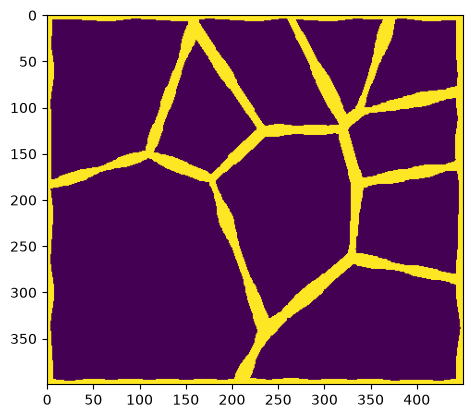

In [11]:
erosion = get_erosion_mask(edges, noise, MAX_RADIUS)

plt.imshow(erosion)
plt.show()

In [12]:
def apply_erosion_to_parts(
        parts: np.ndarray,
        erosion: np.ndarray,
) -> np.ndarray:
    return np.where(erosion, NUM_PIECES, parts)

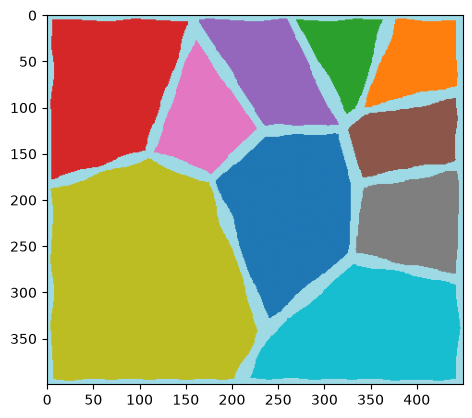

In [13]:
eroded_parts = apply_erosion_to_parts(parts, erosion)

plt.imshow(eroded_parts, cmap='tab20', vmin=0, vmax=NUM_PIECES)
plt.show()

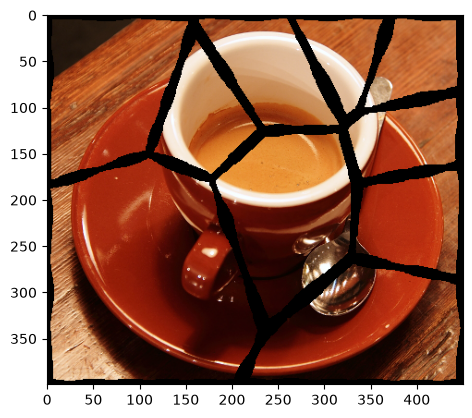

In [14]:
# Example of the eroded parts as should be reconstructed
erosion_ = np.stack([erosion, erosion, erosion], axis=-1)
plt.imshow(np.where(erosion_ , 0, image))
plt.show()

In [15]:
def get_random_pair(
    image: np.ndarray,
    parts: np.ndarray,
    neighbors_graph: Dict[int, Set[int]],
    crop: bool = False,
    seed: Optional[int] = None
) -> Tuple[Tuple[np.ndarray, np.ndarray], Tuple[int, int]]:
    """Selects a random adjacent pair of pieces from a segmentation map and extracts them.

    Args:
        image: The source RGB image array of shape (height, width, 3).
        parts: 2D array of region/piece labels matching the image dimensions.
        neighbors_graph: Dictionary mapping each piece index to its list of neighbor indices.
        crop: Whether to crop the extracted pieces to their tight bounding boxes.
        seed: Optional random seed for reproducible pair selection.

    Returns:
        A tuple containing:
            - A tuple of two numpy arrays representing the extracted pieces (piece1, piece2).
            - A tuple of the two selected piece indices (idx1, idx2).
    """
    rng = np.random.default_rng(seed)
    num_pieces = len(neighbors_graph)
    
    # Select an initial piece index, ensuring it has valid neighbors
    while True:
        idx1 = int(rng.integers(0, num_pieces))
        neighbors = neighbors_graph.get(idx1, [])
        if neighbors:
            break
            
    idx2 = int(rng.choice(list(neighbors)))
    
    def extract_and_crop(idx: int) -> np.ndarray:
        """Helper to extract a single piece, optionally cropping to its bounding box."""
        mask = parts == idx
        y_indices, x_indices = np.where(mask)
        
        # Handle empty masks gracefully
        if len(y_indices) == 0 or len(x_indices) == 0:
            return np.zeros((0, 0, 3), dtype=image.dtype)
        
        if crop:
            ymin, ymax = y_indices.min(), y_indices.max()
            xmin, xmax = x_indices.min(), x_indices.max()
            
            cropped_mask = mask[ymin:ymax+1, xmin:xmax+1]
            cropped_image = image[ymin:ymax+1, xmin:xmax+1]
            active_mask = cropped_mask
            active_image = cropped_image
        else:
            active_mask = mask
            active_image = image
            
        # Broadcast mask across RGB channels and apply zero-background
        rgb_mask = np.stack([active_mask, active_mask, active_mask], axis=-1)
        return np.where(rgb_mask, active_image, 0)

    piece1 = extract_and_crop(idx1)
    piece2 = extract_and_crop(idx2)
    
    return (piece1, piece2), (idx1, idx2)

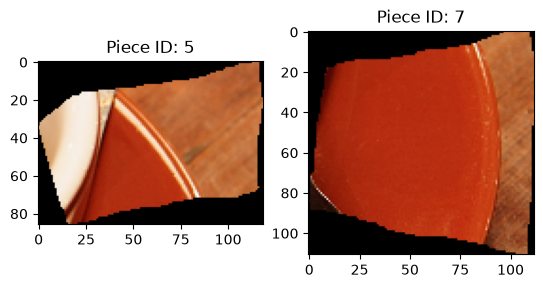

In [16]:
pieces, indices = get_random_pair(image, eroded_parts, neighbor_graph, crop=True, seed=SEED)

# Plot two pieces side by side
fig, axes = plt.subplots(1, 2)
axes[0].imshow(pieces[0])
axes[0].set_title(f"Piece ID: {indices[0]}")
axes[1].imshow(pieces[1])
axes[1].set_title(f"Piece ID: {indices[1]}")
plt.show()